In [1]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames
using MLJ
using Dates
using JuMP, Ipopt
using LinearAlgebra

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

["2017-01-02 00:00:00", "2017-01-02 01:00:00", "2017-01-02 02:00:00"]
γ = 4.0, λ = 0.0005 → val RMSE = 0.1691
γ = 4.0, λ = 0.0002 → val RMSE = 0.1691
γ = 4.0, λ = 0.0001 → val RMSE = 0.1692
γ = 4.0, λ = 7.5e-5 → val RMSE = 0.1692
γ = 4.0, λ = 5.0e-5 → val RMSE = 0.1692
γ = 4.5, λ = 0.0005 → val RMSE = 0.168
γ = 4.5, λ = 0.0002 → val RMSE = 0.168
γ = 4.5, λ = 0.0001 → val RMSE = 0.168
γ = 4.5, λ = 7.5e-5 → val RMSE = 0.168
γ = 4.5, λ = 5.0e-5 → val RMSE = 0.168
γ = 5.0, λ = 0.0005 → val RMSE = 0.1671
γ = 5.0, λ = 0.0002 → val RMSE = 0.1671
γ = 5.0, λ = 0.0001 → val RMSE = 0.1671
γ = 5.0, λ = 7.5e-5 → val RMSE = 0.1671
γ = 5.0, λ = 5.0e-5 → val RMSE = 0.1671
γ = 6.0, λ = 0.0005 → val RMSE = 0.1661
γ = 6.0, λ = 0.0002 → val RMSE = 0.1661
γ = 6.0, λ = 0.0001 → val RMSE = 0.1661
γ = 6.0, λ = 7.5e-5 → val RMSE = 0.1661
γ = 6.0, λ = 5.0e-5 → val RMSE = 0.1661
γ = 7.0, λ = 0.0005 → val RMSE = 0.1657
γ = 7.0, λ = 0.0002 → val RMSE = 0.1657
γ = 7.0, λ = 0.0001 → val RMSE = 0.1657
γ = 7.0, λ = 7.

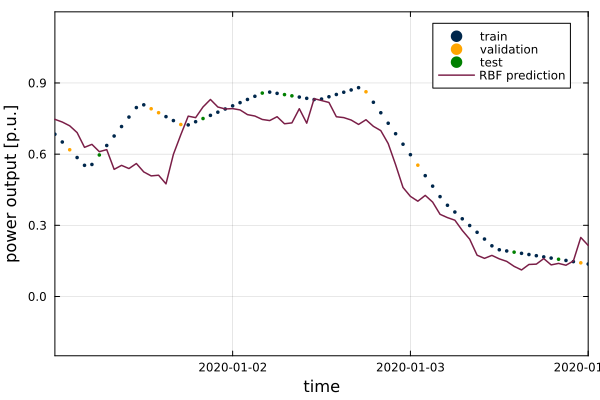

In [ ]:
# 4 
# Example with new data, data split, time sorting
# Data from the kaggle data set sorted by time, data set split into training, validation, testing, multiple wind features

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")

m     = nrow(df)
times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m)  ./ 10.0
x100m = Float64.(df.windspeed_100m) ./ 10.0
x10g  = Float64.(df.windgusts_10m) ./ 10.0

train, val, test = partition(eachindex(t), 0.8, 0.1; shuffle = true, rng = 128)

c_max = max(1.1, maximum(x10m), maximum(x100m)) + 0.05
c = collect(0.0:0.05:c_max)
num_centers = length(c)

# RBF features for one input
function rbf_features(xs, γ)
    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    return Φ
end

design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

function train_rbf(Φ, t; α = 0.01, n_epochs = 20, λ = 0.001,
                   reg_type = :l2, seed = 128)
    reg_type in (:l2, :l1, :none) ||
        error("reg_type must be :l2, :l1, or :none, got $reg_type")

    rng    = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    nfeat  = size(Φ, 2)
    w_0    = 0.0
    w      = zeros(nfeat)

    for epoch in 1:n_epochs
        for i in shuffle(rng, 1:ntrain)       # each sample visited once per epoch
            ϕi  = @view Φ[i, :]               # no allocation
            err = (w_0 + dot(ϕi, w)) - t[i]

            w_0 -= α * err
            w   .-= α * err .* ϕi

            if reg_type == :l2
                w .-= α * λ .* w
            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
            end
        end
    end
    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

# ---------- Hyperparameter selection on the validation set ----------
λ_grid = [5e-4, 2e-4, 1e-4, 7.5e-5, 5e-5]
γ_grid = [ 4.0, 4.5, 5.0, 6.0, 7.0,]

best = (rmse = Inf, λ = NaN, γ = NaN)
for γ in γ_grid, λ in λ_grid
    Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ)
    Φ_val   = design_matrix(x10m[val],   x100m[val], x10g[val],  γ)
    w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)
    score   = rmse(predict_rbf(Φ_val, w_0, w), t[val])
    println("γ = $γ, λ = $λ → val RMSE = $(round(score, digits = 4))")
    if score < best.rmse
        global best = (rmse = score, λ = λ, γ = γ)
    end
end
println("Best: ", best)

# ---------- Final fit and test evaluation ----------
γ, λ = best.γ, best.λ

Φ_train = design_matrix(x10m[train], x100m[train], x10g[train], γ)
w_0, w  = train_rbf(Φ_train, t[train]; λ = λ)

Φ_test = design_matrix(x10m[test], x100m[test], x10g[test], γ)

# ---------- Plot (by time) ----------
ŷ = predict_rbf(design_matrix(x10m, x100m, x10g, γ), w_0, w)   # one prediction per timestamp

plo = scatter(times[train], t[train], c = blue, label = "train",
              ms = 2, markerstrokewidth = 0, frame = :box,
              xlabel = "time", ylabel = "power output [p.u.]")
scatter!(plo, times[val],  t[val],  c = :orange, ms = 2, markerstrokewidth = 0, label = "validation")
scatter!(plo, times[test], t[test], c = :green,  ms = 2, markerstrokewidth = 0, label = "test")
plot!(plo, times, ŷ, lw = 1.5, c = purple, label = "RBF prediction")
plot!(plo, ylims = (-0.25, 1.2))

# Zoom into two weeks if the data spans a long period (adjust the year):
plot!(plo, xlims = (DateTime(2020, 1, 1), DateTime(2020, 1, 4)))

display(plo)

γ = 4.0, λ = 0.0005 → val RMSE = 0.1727
γ = 4.0, λ = 0.0002 → val RMSE = 0.1726
γ = 4.0, λ = 0.0001 → val RMSE = 0.1726
γ = 4.0, λ = 7.5e-5 → val RMSE = 0.1726
γ = 4.0, λ = 5.0e-5 → val RMSE = 0.1725
γ = 4.5, λ = 0.0005 → val RMSE = 0.172
γ = 4.5, λ = 0.0002 → val RMSE = 0.172
γ = 4.5, λ = 0.0001 → val RMSE = 0.1719
γ = 4.5, λ = 7.5e-5 → val RMSE = 0.1719
γ = 4.5, λ = 5.0e-5 → val RMSE = 0.1719
γ = 5.0, λ = 0.0005 → val RMSE = 0.1715
γ = 5.0, λ = 0.0002 → val RMSE = 0.1715
γ = 5.0, λ = 0.0001 → val RMSE = 0.1714
γ = 5.0, λ = 7.5e-5 → val RMSE = 0.1714
γ = 5.0, λ = 5.0e-5 → val RMSE = 0.1714
γ = 6.0, λ = 0.0005 → val RMSE = 0.1708
γ = 6.0, λ = 0.0002 → val RMSE = 0.1707
γ = 6.0, λ = 0.0001 → val RMSE = 0.1707
γ = 6.0, λ = 7.5e-5 → val RMSE = 0.1707
γ = 6.0, λ = 5.0e-5 → val RMSE = 0.1707
γ = 7.0, λ = 0.0005 → val RMSE = 0.1704
γ = 7.0, λ = 0.0002 → val RMSE = 0.1703
γ = 7.0, λ = 0.0001 → val RMSE = 0.1703
γ = 7.0, λ = 7.5e-5 → val RMSE = 0.1703
γ = 7.0, λ = 5.0e-5 → val RMSE = 0.1703
Be

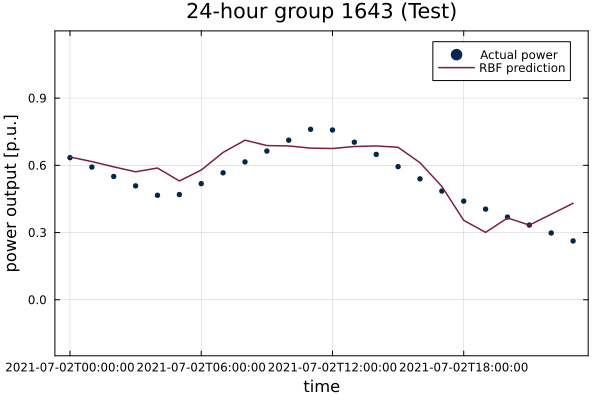

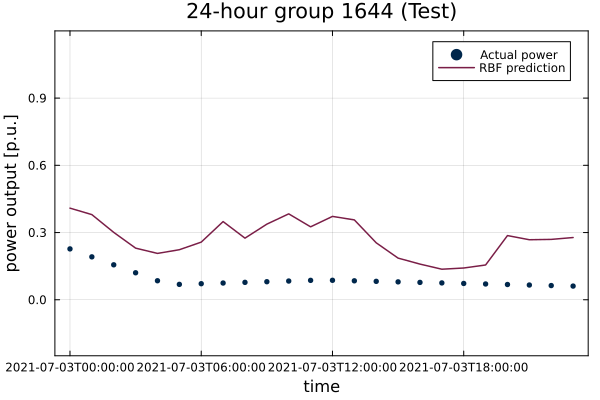

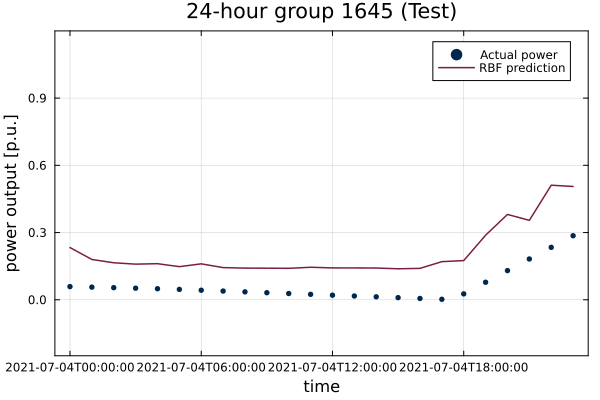

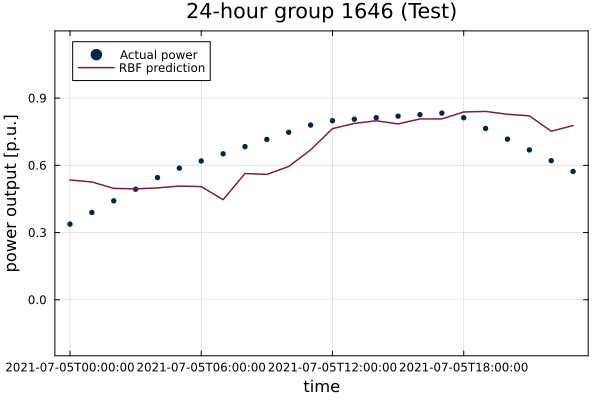

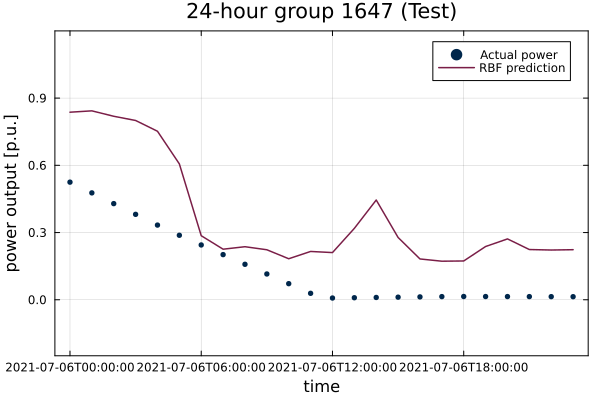

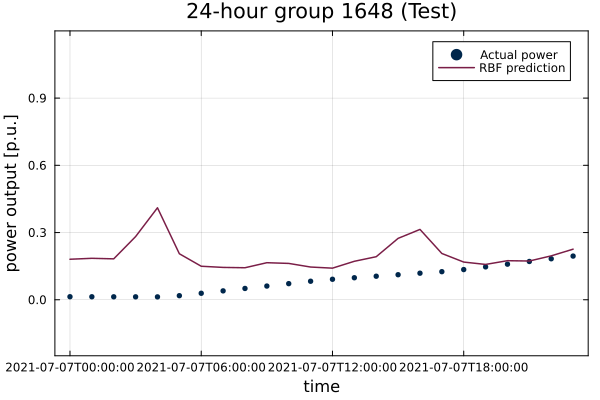

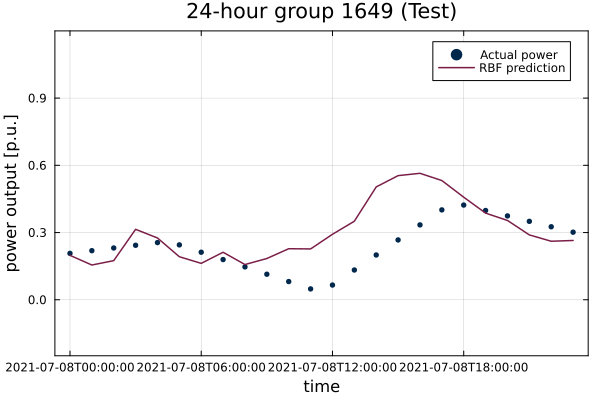

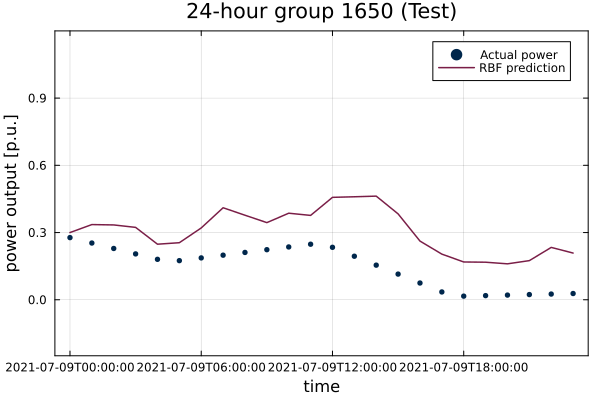

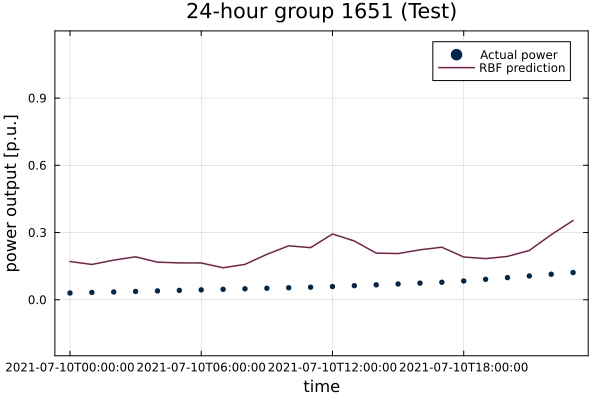

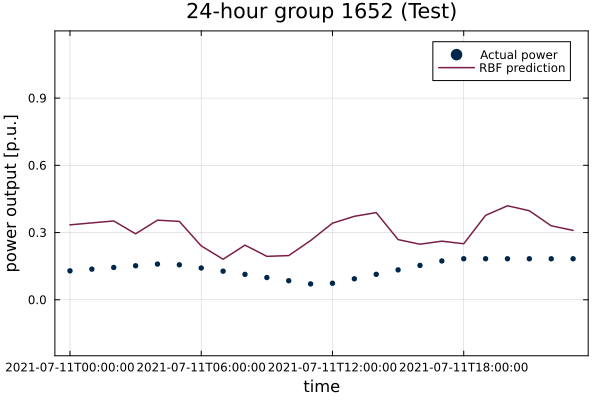

In [3]:
# 5
# 24-hour grouped data splitting with single-output SGD
# Each hourly observation produces one independent prediction

df = CSV.read("location1.csv", DataFrame; types = Dict(:Time => String))
df.Time = DateTime.(df.Time, dateformat"yyyy-mm-dd HH:MM:SS")

m     = nrow(df)
times = df.Time
t     = Float64.(df.Power)
x10m  = Float64.(df.windspeed_10m) ./ maximum(df.windspeed_10m)
x100m = Float64.(df.windspeed_100m) ./ maximum(df.windspeed_100m)
x10g  = Float64.(df.windgusts_10m) ./ maximum(df.windgusts_10m)

# ---------- Create 24-hour groups ----------
hours_per_group = 24
num_groups = div(m, hours_per_group)

m_used = num_groups * hours_per_group

# Use only complete 24-hour groups
times = times[1:m_used]
t     = t[1:m_used]
x10m  = x10m[1:m_used]
x100m = x100m[1:m_used]
x10g  = x10g[1:m_used]

# Split complete groups into training, validation, and testing
train, val, test = partition(1:num_groups, 0.8, 0.1;shuffle = false,rng = 120)

c = collect(0.0:0.05:1)
num_centers = length(c)

function rbf_features(xs, γ)

    Φ = zeros(length(xs), num_centers)

    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end

    return Φ
end

design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ),rbf_features(x2, γ),rbf_features(x3, γ))

function grouped_design_matrix(x1, x2, x3, γ, num_groups, hours_per_group)
    Φ_all = design_matrix(x1, x2, x3, γ)
    return Φ_all
end


Y_all = t

# ---------- Convert group indices into hourly indices ----------

function group_to_indices(groups, hours_per_group)

    return vcat([
        ((g - 1) * hours_per_group + 1):(g * hours_per_group)
        for g in groups
    ]...)
end

train_idx = group_to_indices(train, hours_per_group)
val_idx   = group_to_indices(val, hours_per_group)
test_idx  = group_to_indices(test, hours_per_group)

# ---------- Single-output SGD training ----------

function train_rbf(Φ, t; α = 0.01, n_epochs = 20, λ = 0.001,reg_type = :l2, seed = 128)
    
    rng = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    nfeat  = size(Φ, 2)
    w_0 = 0.0
    w   = zeros(nfeat)

    for epoch in 1:n_epochs
        for i in shuffle(rng, 1:ntrain)

            ϕi = @view Φ[i, :]
            err = (w_0 + dot(ϕi, w)) - t[i]
            w_0 -= α * err
            w   .-= α * err .* ϕi

            if reg_type == :l2
                w .-= α * λ .* w

            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)
            end
        end
    end
    return w_0, w
end


predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w
rmse(y_pred, y_actual) = sqrt(mean((y_pred .- y_actual).^2))

λ_grid = [5e-4, 2e-4, 1e-4, 7.5e-5, 5e-5]
γ_grid = [4.0, 4.5, 5.0, 6.0, 7.0]

best = (rmse = Inf, λ = NaN, γ = NaN)

for γ in γ_grid, λ in λ_grid

    Φ_all = grouped_design_matrix(
        x10m, x100m, x10g, γ, num_groups, hours_per_group
    )

    # Select hourly observations belonging to each group
    Φ_train = Φ_all[train_idx, :]
    Φ_val   = Φ_all[val_idx, :]

    Y_train = Y_all[train_idx]
    Y_val   = Y_all[val_idx]

    # Train single-output model
    w_0, w = train_rbf(Φ_train, Y_train; λ = λ)

    # Predict each validation hour independently
    Y_val_pred = predict_rbf(Φ_val, w_0, w)

    score = rmse(Y_val_pred, Y_val)

    println(
        "γ = $γ, λ = $λ → val RMSE = $(round(score, digits = 4))"
    )

    if isfinite(score) && score < best.rmse
        global best = (rmse = score, λ = λ, γ = γ)
    end
end

println("Best: ", best)

# ---------- Final fit and test evaluation ----------

γ, λ = best.γ, best.λ

Φ_all = grouped_design_matrix(
    x10m, x100m, x10g, γ, num_groups, hours_per_group
)

Φ_train = Φ_all[train_idx, :]
Y_train = Y_all[train_idx]

# Train final model using training groups
w_0, w = train_rbf(Φ_train, Y_train; λ = λ)

# Test predictions
Φ_test = Φ_all[test_idx, :]
Y_test = Y_all[test_idx]

Y_test_pred = predict_rbf(Φ_test, w_0, w)

test_rmse = rmse(Y_test_pred, Y_test)

println("Test RMSE = ", round(test_rmse, digits = 4))

# Predictions for every hourly observation
Y_pred = predict_rbf(Φ_all, w_0, w)

# ---------- Plot each 24-hour group ----------

for group in test[1:min(10, length(test))]

    idx = ((group - 1) * hours_per_group + 1):(group * hours_per_group)

    plo = scatter(times[idx], Y_all[idx], c = blue, label = "Actual power", ms = 3, markerstrokewidth = 0, frame = :box, xlabel = "time", ylabel = "power output [p.u.]", title = "24-hour group $group (Test)")
    plot!(plo, times[idx], Y_pred[idx], lw = 1.5, c = purple, label = "RBF prediction")
    plot!(plo, ylims = (-0.25, 1.2))

    display(plo)
end


Best: (rmse = 0.16669693137835742, λ = 0.04, γ = 5)
Final validation RMSE = 0.1667
Test RMSE = 0.168


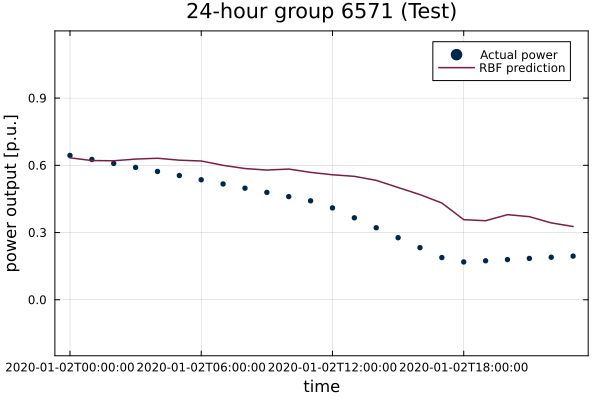

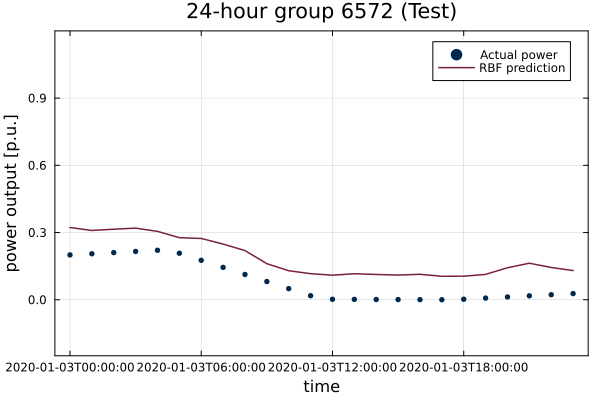

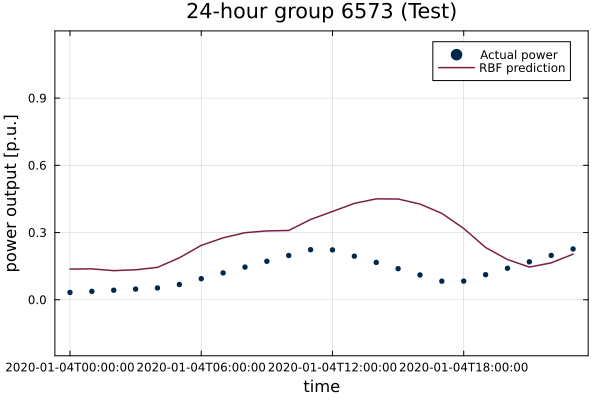

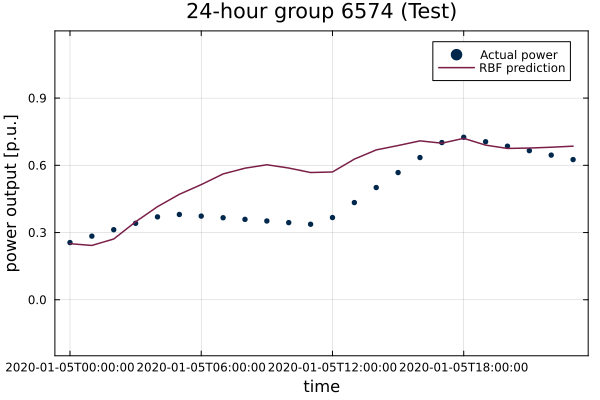

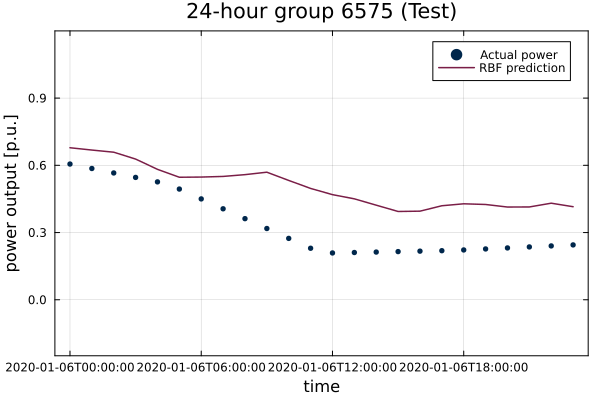

In [4]:
# Load all four locations
dfs = [CSV.read("location$i.csv", DataFrame; types = Dict(:Time => String)) for i in 1:4]

# Convert timestamps and assign location IDs
for (i, data) in enumerate(dfs)
    data.Time = DateTime.(data.Time, dateformat"yyyy-mm-dd HH:MM:SS")
    data.LocationID = fill(i, nrow(data))
end

# Combine all locations and sort by location and time
df = vcat(dfs...)
sort!(df, [:LocationID, :Time])

m     = nrow(df)
times = df.Time
t     = Float64.(df.Power)

# Normalize weather features across all four locations
x10m  = Float64.(df.windspeed_10m) ./ maximum(df.windspeed_10m)
x100m = Float64.(df.windspeed_100m) ./ maximum(df.windspeed_100m)
x10g  = Float64.(df.windgusts_10m) ./ maximum(df.windgusts_10m)

# 24-hour groups
hours_per_group = 24
num_groups = div(m, hours_per_group)

m_used = num_groups * hours_per_group

times = times[1:m_used]
t     = t[1:m_used]
x10m  = x10m[1:m_used]
x100m = x100m[1:m_used]
x10g  = x10g[1:m_used]

location_ids = df.LocationID[1:m_used]

train, val, test = partition(1:num_groups, 0.8, 0.1;shuffle = false,rng = 120)

c = collect(0.0:0.075:1)
num_centers = length(c)

function rbf_features(xs, γ)

    Φ = zeros(length(xs), num_centers)
    for i in eachindex(xs), j in 1:num_centers
        Φ[i, j] = exp(-(γ * abs(xs[i] - c[j]))^2)
    end
    
    return Φ
end

weather_design_matrix(x1, x2, x3, γ) = hcat(rbf_features(x1, γ), rbf_features(x2, γ), rbf_features(x3, γ))

grouped_design_matrix(x1, x2, x3, lag_power, γ) = hcat(weather_design_matrix(x1, x2, x3, γ), lag_power)
Y_all = t

group_to_indices(groups, hours_per_group) = vcat([((g - 1) * hours_per_group + 1):(g * hours_per_group) for g in groups]...)

train_idx = group_to_indices(train, hours_per_group)
val_idx   = group_to_indices(val, hours_per_group)
test_idx  = group_to_indices(test, hours_per_group)

train_idx_fit = filter(i -> i > 1, train_idx)

function train_rbf(Φ, t;α = 0.02,n_epochs = 20,λ = 0.001,reg_type = :l2,seed = 128)

    rng = MersenneTwister(seed)
    ntrain = size(Φ, 1)
    nfeat  = size(Φ, 2)
    w_0 = 0.0
    w   = zeros(nfeat)

    for epoch in 1:n_epochs
        for i in shuffle(rng, 1:ntrain)

            ϕi = @view Φ[i, :]
            err = (w_0 + dot(ϕi, w)) - t[i]
            w_0 -= α * err
            w   .-= α * err .* ϕi

            if reg_type == :l2
                w .-= α * λ .* w

            elseif reg_type == :l1
                w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

            end
        end
    end

    return w_0, w
end

predict_rbf(Φ, w_0, w) = w_0 .+ Φ * w

rmse(y_pred, y_actual) = sqrt(mean((y_pred .- y_actual).^2))


# ---------- Recursive prediction ----------

function predict_recursive(Φ_weather, indices, initial_lag, w_0, w)

    n = length(indices)
    predictions = zeros(n)
    previous_power = initial_lag

    for j in 1:n

        # Weather features for the current hour
        ϕ_weather = @view Φ_weather[indices[j], :]

        # Append raw previous-hour power
        ϕ = vcat(collect(ϕ_weather), previous_power)

        # Make current prediction
        prediction = w_0 + dot(ϕ, w)

        # Keep prediction within normalized power range
        prediction = clamp(prediction, 0.0, 1.0)

        predictions[j] = prediction

        # Feed prediction into the next hourly observation
        previous_power = prediction

    end

    return predictions
end


# ---------- Hyperparameter search ----------

λ_grid = [ 4e-2, 5e-2, 6e-2]
γ_grid = [5]

best = (rmse = Inf, λ = NaN, γ = NaN)

# Initial validation lag:
# Actual power from the final training observation
initial_val_lag = t[first(val_idx) - 1]

for γ in γ_grid, λ in λ_grid

    Φ_weather = weather_design_matrix(x10m, x100m, x10g, γ)
    lag_train = t[train_idx_fit .- 1]
    
    Φ_train = grouped_design_matrix(x10m[train_idx_fit],x100m[train_idx_fit],x10g[train_idx_fit],lag_train,γ)
    Y_train = Y_all[train_idx_fit]

    w_0, w = train_rbf(Φ_train, Y_train; λ = λ)

    Y_val_pred = predict_recursive(Φ_weather, val_idx, initial_val_lag, w_0, w)
    Y_val = Y_all[val_idx]

    score = rmse(Y_val_pred, Y_val)

    if isfinite(score) && score < best.rmse
        global best = (rmse = score,λ = λ,γ = γ)
    end
end

println("Best: ", best)

# ---------- Final fit and test evaluation ----------

γ, λ = best.γ, best.λ

Φ_weather = weather_design_matrix(x10m, x100m, x10g, γ)

# Training lag uses actual previous-hour measurements
lag_train = t[train_idx_fit .- 1]

Φ_train = grouped_design_matrix(x10m[train_idx_fit],x100m[train_idx_fit],x10g[train_idx_fit],lag_train,γ)
Y_train = Y_all[train_idx_fit]

# Train final model
w_0, w = train_rbf(Φ_train, Y_train; λ = λ)

# ---------- Validation predictions ----------

Y_val_pred = predict_recursive(Φ_weather,val_idx,initial_val_lag,w_0,w)
Y_val = Y_all[val_idx]
val_rmse = rmse(Y_val_pred, Y_val)

println("Final validation RMSE = ", round(val_rmse, digits = 4))


# ---------- Test predictions ----------

# Continue recursively from the final validation prediction
initial_test_lag = t[first(test_idx) - 1]

Y_test_pred = predict_recursive(Φ_weather, test_idx, initial_test_lag, w_0, w)
Y_test = Y_all[test_idx]
test_rmse = rmse(Y_test_pred, Y_test)

println("Test RMSE = ", round(test_rmse, digits = 4))


# ---------- Predictions for every hourly observation ----------

Y_pred = fill(NaN, m_used)

# Training predictions use actual previous-hour measurements
Φ_train_all = grouped_design_matrix(x10m[train_idx_fit],x100m[train_idx_fit],x10g[train_idx_fit],t[train_idx_fit .- 1],γ)

Y_pred[train_idx_fit] .= clamp.(predict_rbf(Φ_train_all, w_0, w),0.0,1.0)
# Validation predictions
Y_pred[val_idx] .= Y_val_pred
# Test predictions
Y_pred[test_idx] .= Y_test_pred

# ---------- Plot each 24-hour group ----------

for group in test[1:min(5, length(test))]

    idx = ((group - 1) * hours_per_group + 1):(group * hours_per_group)

    plo = scatter(times[idx], Y_all[idx], c = blue, label = "Actual power", ms = 3, markerstrokewidth = 0, frame = :box, xlabel = "time", ylabel = "power output [p.u.]", title = "24-hour group $group (Test)")
    plot!(plo, times[idx], Y_pred[idx], lw = 1.5, c = purple, label = "RBF prediction")
    plot!(plo, ylims = (-0.25, 1.2))

    display(plo)
end
